# Lab 8: Plotting with Cartopy and Gridspec

In this notebook, you'll work with two new approaches to plotting remote sensing data in Python. In the first part of the lab, you'll explore the `cartopy` package for plotting georeferenced data on the global (or subsets of the globe). Next, you'll work with the `gridspec` module to organize a collection of subplots into a nicely presentable figure.


This notebook has three parts:
1. Download vector wind data using NASA's EarthAccess tools
2. Explore the `cartopy` package and generate plots of wind in a regional domain
3. Test plotting figures with `gridspec` module and create a nice figure using a collection of subplots


**Import the modules for this notebook**

In [1]:
# import the modules for accessing and reading data
import os
import numpy as np
import netCDF4 as nc4
import earthaccess

# import the modules for plotting
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
import cmocean.cm as cm

# import the modules for geographic plots
import cartopy
import cartopy.crs as ccrs
import cartopy.io.img_tiles as cimgt

## Part 1: Downloading Vector Wind Data via NASA Earthaccess

In this lab, we will use vector wind data in the [L4 Cross-Calibrated Multi-Platform (CCMP) product](https://www.earthdata.nasa.gov/data/catalog/pocloud-ccmp-winds-10m6hr-l4-v3.1-3.1#overview). Like the previous lab, we'll access this data using a set of tools that NASA provides for gathering data available via Earthdata.

As before, start by defining a folder where the data will be downloaded:

In [2]:
# directory where the files will be stored
data_folder = '../data/labs/lab08'

Next, let's "log in" to the Earthdata. This step will require your Earthdata credentials - if you set up the `.netrc` file as described in the [Registering for Account][../getting_started/register_accounts.md] page, you won't need to do anything in the following cell:

In [3]:
# log in to NASA Earthdata
earthaccess.login();

Up next, we'll provide a query to determine which files exist. Here, let's gather all of the vector wind files for the year 2025. The query using the `earthaccess` module takes the following form:

In [4]:
# Search for all CCMP V3.1 granules during calendar year 2025
granules = earthaccess.search_data(
    short_name="CCMP_WINDS_10M6HR_L4_V3.1",
    version="3.1",
    provider="POCLOUD",
    temporal=(
        "2025-01-01T00:00:00Z",
        "2025-12-31T23:59:59Z",
    ),
    count=-1,              # retrieve all matching granules
    downloadable=True,
)

print(f"Found {len(granules)} granules.")

Found 365 granules.


Ssing our query, we'll download the data using the download command:

In [5]:
# Download files, skipping files already present.
downloaded_files = earthaccess.download(
    granules,
    local_path=data_folder,
    threads=4,
    force=False,
)

print(f"Downloaded {len(downloaded_files)} files.")

QUEUEING TASKS | :   0%|          | 0/365 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/365 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/365 [00:00<?, ?it/s]

Downloaded 365 files.


## Part 2: Plotting with Cartopy

When working with geophysical data, we often want to plot data on a map. We can use the native coordinates of our data to make simple 2D maps, but what if we want to work with different projections and visualizations for our data? Python's `cartopy` package provides a convenient set of tools to plot data on the map.

### Coastlines
The `cartopy` package stores a copy of the global coastlines which can be plotted on a map with any given projection. The code below shows the coastline on the `Robinson` projection:

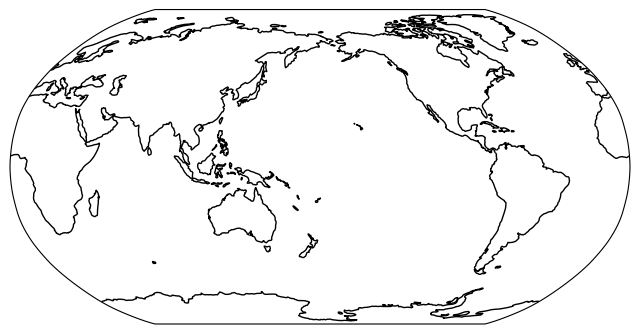

In [6]:
# create a new figure with size (8,5)
fig = plt.figure(figsize=(8,5))

# add a new set of axes with the Robinson projection
ax = plt.axes(projection=ccrs.Robinson(central_longitude=-180))

# add the coastlines
ax.coastlines()

# show the plot
plt.show()

#### Projections
As you can see above, the axes object provides the projection system for the map. The `cartopy` package has a variety of different projections for plotting mapped data. Test some of the common projections in the figure above:

| Projection Code | Default Parameters |
|-----------------|--------------------|
|  PlateCarree()  | central_longitude=0.0 |
| Mollweide()     | central_longitude=0.0 |
| Orthographic()  | central_longitude=0.0, central_latitude=0.0 |
| Robinson()      | central_longitude=0.0 |
| InterruptedGoodeHomolosine() | central_longitude=0.0 |

When you find your favorite projection, try changing the default central longitude/latitude to see how the plot changes.

### Basemaps
Often, we may want to include a *basemap* image to cover parts of the map where we do not have data. `cartopy` has  default built-in image to do just that:

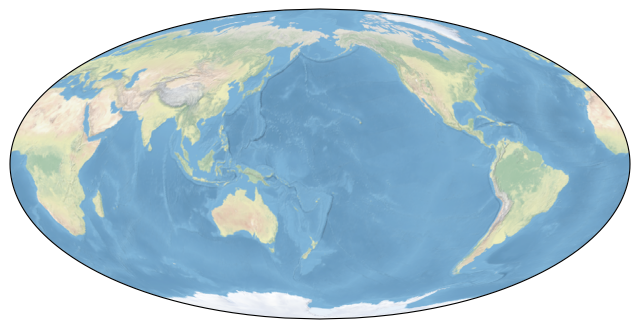

In [7]:
# create a new figure with size (8,5)
fig = plt.figure(figsize=(8,5))

# add a new set of axes with the Mollweide projection
ax = plt.axes(projection=ccrs.Mollweide(central_longitude=-180))

# add the stock image
ax.stock_img()

# show the plot
plt.show()

Basemaps from Google Earth can also be downloaded and plotted:

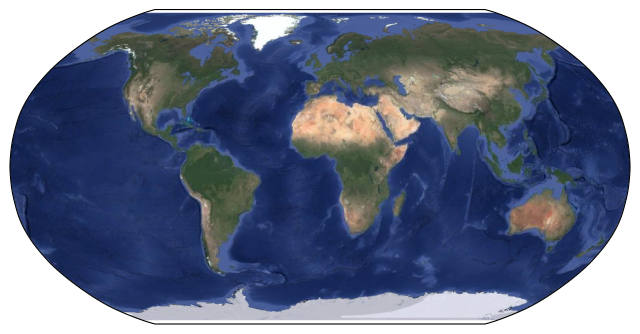

In [8]:
# create a new figure with size (8,5)
fig = plt.figure(figsize=(8,5))

# add a new set of axes with the Robinson projection
ax = plt.axes(projection=ccrs.Robinson())

# add the google earth satellite imagery
request = cimgt.GoogleTiles(style='satellite');
ax.add_image(request, 2)

# show the plot
plt.show()

### Plotting Data on the Projected Map
Now that we have a map in our prefered projection, next we'd like to be able to plot our own data on the map. Begin by reading in one of the vector wind files we download above:

In [9]:
# define a file path to one of the nc files
file_path = os.path.join(data_folder, 'CCMP_Wind_Analysis_20250101_V03.1_L4.nc')

# open the file and read in the data
ds = nc4.Dataset(file_path)
longitude = np.array(ds.variables['longitude'])
latitude = np.array(ds.variables['latitude'])
u_wind_speed = ds.variables['uwnd'][:,:,:]
v_wind_speed = ds.variables['vwnd'][:,:,:]
ds.close()

# compute the wind speed
wind_speed = (u_wind_speed**2 + v_wind_speed**2)**0.5

Below, we'll plot this data on the globe. However, first let's define our own custom colormap to approximate the visualization on the popular weather app [Windy.com](https://www.windy.com/):

In [10]:
windy_colors = [
    (0.00, "#5b69c2"),  # 0 m/s: deep blue
    (0.10, "#4e69b8"),  # 3 m/s: blue
    (0.15, "#4887ad"),  # 6 m/s: blue-teal
    (0.33, "#559e65"),  # 10 m/s: green
    (0.40, "#649e32"),  # 15 m/s: yellow-green
    (0.50, "#a78541"),  # 18 m/s: olive/tan
    (0.66, "#934a54"),  # 21 m/s: red-brown
    (0.80, "#7c3578"),  # 24 m/s: purple
    (0.90, "#5768a5"),  # 27 m/s: blue-purple
    (1.00, "#5c89a7"),  # 30 m/s: blue-gray
]

windy_cmap = mcolors.LinearSegmentedColormap.from_list("windy_wind", windy_colors)

With our data and wind colormap in hand, we're ready to plot the data. The cartopy plotting uses the same structure as typical plots - the only difference is that the projection information needs to be provided at each relevant location. Take a look at the following example:

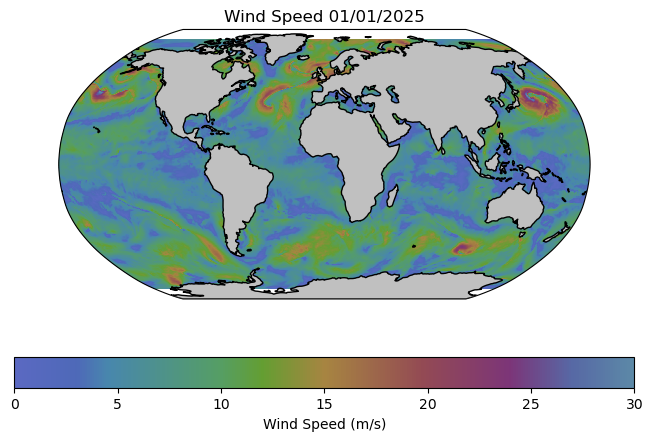

In [11]:
# create a new figure with size (8,5)
fig = plt.figure(figsize=(8,5))

# add a new set of axes with the Robinson projection
ax = plt.axes(projection=ccrs.Robinson())

# use pcolormesh to plot the data as before
# pass a new argument for transform=ccrs.PlateCarree()
C = plt.pcolormesh(longitude, latitude, wind_speed[0,:,:],
                   vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())

# add a colorbar with a label below the plot
cbar = plt.colorbar(C, orientation='horizontal')
cbar.set_label('Wind Speed (m/s)')

# add land features over the data
ax.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')

# add a title to the plot with the date
plt.title('Wind Speed 01/01/2025')

# show the plot
plt.show()

```{note}
In `cartopy`, the `projection` describes how the map is displayed while the `transform` describes the coordinate system of the data being plotted. As we can see above, we use `transform=ccrs.PlateCarree()` when plotting the wind data because the coordinates are stored as longitude and latitude even when the map itself uses a `Robinson` projection.
```

#### Creating a regional map in a projected coordinate system
Just as with regular 2D plots, we can plot just a subset of the data using the `extent` list. Just like the plotting of the data on the map, however, we will also need to projection information. We can modify the plot above be just in a subset around Central America by defining an extent with longitude in the range -125 to -75, and latitude in the range 0 to 30.

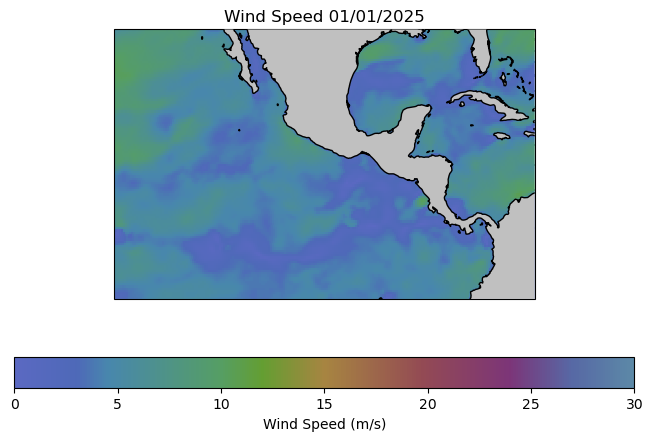

In [12]:
# create a new figure with size (8,5)
fig = plt.figure(figsize=(8,5))

# add a new set of axes with the Robinson projection
ax = plt.axes(projection=ccrs.Robinson())

# use pcolormesh to plot the data as before
# pass a new argument for transform=ccrs.PlateCarree()
C = plt.pcolormesh(longitude, latitude, wind_speed[0,:,:],
                   vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())

# add a colorbar with a label below the plot
cbar = plt.colorbar(C, orientation='horizontal')
cbar.set_label('Wind Speed (m/s)')

# add land features over the data
ax.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')

# add a title to the plot with the date
plt.title('Wind Speed 01/01/2025')

# change the extent
ax.set_extent([-125, -75, 0, 30], ccrs.PlateCarree())

# show the plot
plt.show()

### Rotating a Plot
Often, we want our maps to be focused on our particular region of the global ocean. For example, we may want to center our plot on the Pacific Ocean when this is the focus of our study area. To do this, we can use the `central_longitude` and `central_latitude` keywords in the projections. Let's check this out with the `Orthographic` projection:

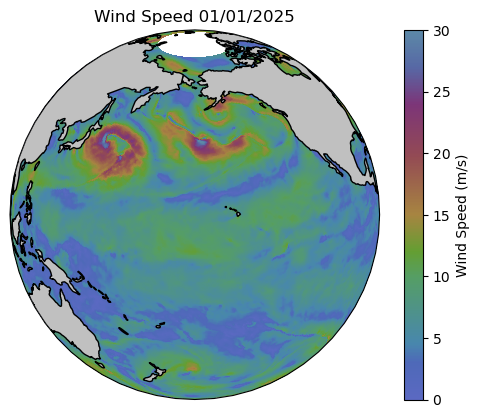

In [13]:
# copy the (global) code block above with  minimal comments to highlight the rotation
plt.figure()

# add a rotation to the Orthographic projection
ax = plt.axes(projection=ccrs.Orthographic(central_longitude = -170, central_latitude=20))

# same code as provided above
C = plt.pcolormesh(longitude, latitude, wind_speed[0,:,:],
                   transform=ccrs.PlateCarree(), vmin=0, vmax=30, cmap=windy_cmap)
cbar = plt.colorbar(C)
cbar.set_label('Wind Speed (m/s)')
ax.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
plt.title('Wind Speed 01/01/2025')
plt.show()

### Adding Longitude and Latitude Lines
Often a coordinate system is advantageous on projected maps to provide a geographic context. Longitude and latitude lines can be added with the help of the `matplotlib.ticker` module. Here is an example with the `Orthographic` projection:

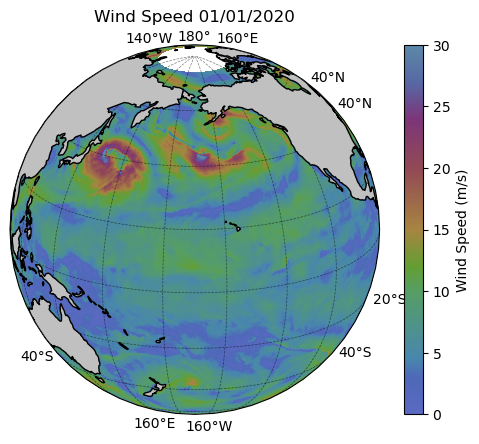

In [14]:
plt.figure()
ax = plt.axes(projection=ccrs.Orthographic(central_longitude = -170, central_latitude=20))
C = plt.pcolormesh(longitude, latitude, wind_speed[0,:,:],
                   transform=ccrs.PlateCarree(), vmin=0, vmax=30, cmap=windy_cmap)
cbar = plt.colorbar(C)
cbar.set_label('Wind Speed (m/s)')
ax.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
plt.title('Wind Speed 01/01/2020')

# before showing the plot, add gridlines with crs=ccrs.PlateCarree()
gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.5, color='black', alpha=0.5, linestyle='--', draw_labels=True)

# use the xlocator and ylocator attributes to determine the location of the lon/lat lines
gl.xlocator = mticker.FixedLocator([120, 140, 160, 180, -160, -140, -120])
gl.ylocator = mticker.FixedLocator([-60, -40, -20, 0, 20, 40, 60])

plt.show()

### &#129300; Try it for yourself
Using the code above as an example data set, generate a similar plot in a region which fits your interests. Test out different projections and colorbars to get familiar with `cartopy` and create a nice figure for your region.

## Part 3: Plotting Figures with Multiple Panels

When comparing data, we often want to look at different snapshots in time on the same figure. In this notebook, we will investigate `matplotlib`'s `gridspec` module to arrange subplots on the same figure.

### Plots with 4 Panels
In the plot below, we will investigate snapshots of global wind speeds in 4 distinct months: January, April, July, and October. The `Gridspec` module allows us to control the layout of a figure with multiple panels. Begin identifying 4 files in the months listed above. Then, read in the grid for each file.

In [15]:
# define the file name of the 4 files
january_file = os.path.join(data_folder, 'CCMP_Wind_Analysis_20250101_V03.1_L4.nc')
april_file = os.path.join(data_folder, 'CCMP_Wind_Analysis_20250401_V03.1_L4.nc')
july_file = os.path.join(data_folder, 'CCMP_Wind_Analysis_20250701_V03.1_L4.nc')
october_file = os.path.join(data_folder, 'CCMP_Wind_Analysis_20251001_V03.1_L4.nc')

Using the files above, read in the data:

In [16]:
# read in the data from each of the files above,
# storing in grids as january_windspeed, april_windspeed, etc
# for one of the files, also read in the lon/lat info
ds = nc4.Dataset(january_file)
longitude = np.array(ds.variables['longitude'])
latitude = np.array(ds.variables['latitude'])
u_wind_speed = ds.variables['uwnd'][:,:,:]
v_wind_speed = ds.variables['vwnd'][:,:,:]
ds.close()
january_windspeed = (u_wind_speed**2 + v_wind_speed**2)**0.5

ds = nc4.Dataset(april_file)
u_wind_speed = ds.variables['uwnd'][:,:,:]
v_wind_speed = ds.variables['vwnd'][:,:,:]
ds.close()
april_windspeed = (u_wind_speed**2 + v_wind_speed**2)**0.5

ds = nc4.Dataset(july_file)
u_wind_speed = ds.variables['uwnd'][:,:,:]
v_wind_speed = ds.variables['vwnd'][:,:,:]
ds.close()
july_windspeed = (u_wind_speed**2 + v_wind_speed**2)**0.5

ds = nc4.Dataset(october_file)
u_wind_speed = ds.variables['uwnd'][:,:,:]
v_wind_speed = ds.variables['vwnd'][:,:,:]
ds.close()
october_windspeed = (u_wind_speed**2 + v_wind_speed**2)**0.5

Next, use `GridSpec` to arrange the plots in a 2 x 2 grid:

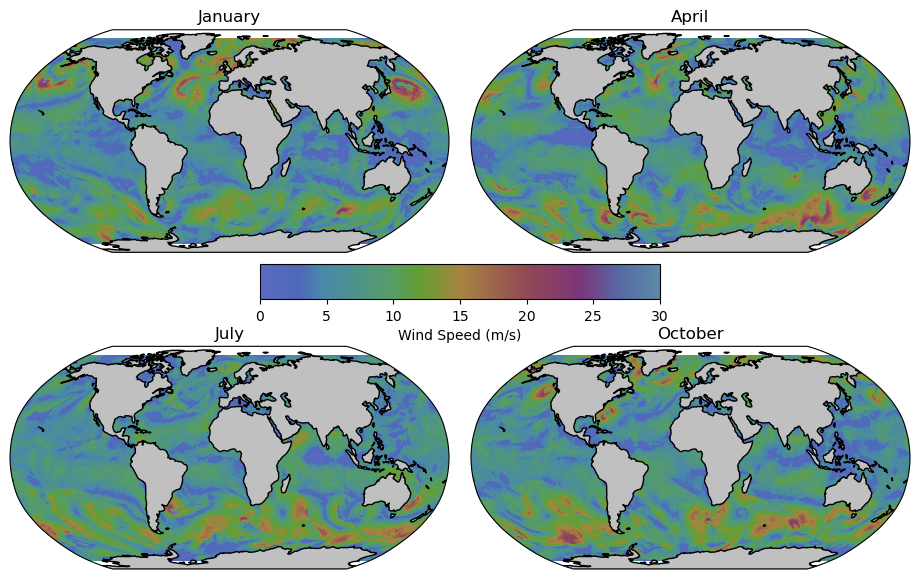

In [17]:
# create a figure with size (10,7)
fig = plt.figure(figsize=(10, 7))

# create a 2x2 GridSpec frame
# use a 5% border, 5% horizonal spacing and 1% vertical spacing
gs = GridSpec(2, 2,
              left=0.05, right=0.95, bottom=0.05, top=0.95,
              hspace=0.01, wspace=0.05)

# add an axis for the january field and plot it
ax1 = fig.add_subplot(gs[0,0], projection=ccrs.Robinson())
ax1.pcolormesh(longitude, latitude, january_windspeed[0,:,:],
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax1.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax1.set_title('January')

# add an axis for the april field and plot it
ax2 = fig.add_subplot(gs[0,1], projection=ccrs.Robinson())
ax2.pcolormesh(longitude, latitude, april_windspeed[0,:,:],
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax2.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax2.set_title('April')

# add an axis for the january field and plot it
ax3 = fig.add_subplot(gs[1,0], projection=ccrs.Robinson())
ax3.pcolormesh(longitude, latitude, july_windspeed[0,:,:],
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax3.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax3.set_title('July')

# add an axis for the january field and plot it
ax4 = fig.add_subplot(gs[1,1], projection=ccrs.Robinson())
C = ax4.pcolormesh(longitude, latitude, october_windspeed[0,:,:],
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax4.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax4.set_title('October')

# add a colorbar axis
# color bar axis is set by x and y, and then width and height
# x = 0.3, y = 0.5
# use width = 0.4, height = 0.05
cax = fig.add_axes([0.3, 0.5, 0.4, 0.05])
fig.colorbar(C, cax=cax, orientation='horizontal')
cax.set_xlabel('Wind Speed (m/s)');

As you can see, each subplot is added into the `gs` object. In addition, the projection information is provided directly into the axis object.

### Generating the Average Wind Speed Fields
In the plot above, we visualize snapshots of wind in a given period. As winds change day to day, investigating means over time (rather than a single snap shot) can give us a sense of longer-term changes through time. 

#### An averaging function
In the previous classes, we've constructed functions to make timeseries. Here, let's define a function that can compute the averages of a set of files given their file paths:

In [18]:
# define a function to compute average wind speed
def compute_average_wind_speed(file_path_list):

    # make the sum and count grids
    sum_grid = np.zeros((720, 1440))
    count = 0

    # loop through the file paths and add the data from
    # each to the sum and count grids
    for file_path in file_path_list:
        
        # get the wind field from the file
        ds = nc4.Dataset(file_path)
        u_wind_speed = ds.variables['uwnd'][:,:,:]
        v_wind_speed = ds.variables['vwnd'][:,:,:]
        ds.close()

        # mask the wind field and add it to the array
        wind_speed = (u_wind_speed**2 + v_wind_speed**2)**0.5

        # add the wind field info to the sum and count grids
        sum_grid += np.sum(wind_speed,axis=0)
        count += np.shape(wind_speed)[0]

    average_grid = np.copy(sum_grid)
    average_grid /= count

    return(average_grid)

Next, use the function to compute averages in January, April, July, and October

In [19]:
# create a list of files that correspond to January 2025
file_path_list = []
for file_name in os.listdir(data_folder):
    if file_name[-3:]=='.nc' and file_name.split('_')[3][:6]=='202501':
        file_path_list.append(data_folder+'/'+file_name)

# compute the average wind speed from this list
january_average_windspeed = compute_average_wind_speed(file_path_list)

In [20]:
# create a list of files that correspond to April 2025
file_path_list = []
for file_name in os.listdir(data_folder):
    if file_name[-3:]=='.nc' and file_name.split('_')[3][:6]=='202504':
        file_path_list.append(data_folder+'/'+file_name)

# compute the average wind speed from this list
april_average_windspeed = compute_average_wind_speed(file_path_list)

In [21]:
# create a list of files that correspond to July 2025
file_path_list = []
for file_name in os.listdir(data_folder):
    if file_name[-3:]=='.nc' and file_name.split('_')[3][:6]=='202507':
        file_path_list.append(data_folder+'/'+file_name)

# compute the average wind speed from this list
july_average_windspeed = compute_average_wind_speed(file_path_list)

In [22]:
# create a list of files that correspond to October 2025
file_path_list = []
for file_name in os.listdir(data_folder):
    if file_name[-3:]=='.nc' and file_name.split('_')[3][:6]=='202510':
        file_path_list.append(data_folder+'/'+file_name)

# compute the average wind speed from this list
october_average_windspeed = compute_average_wind_speed(file_path_list)

Finally, plot the monthly averages in the maps below (same code as above, but updated to averages):

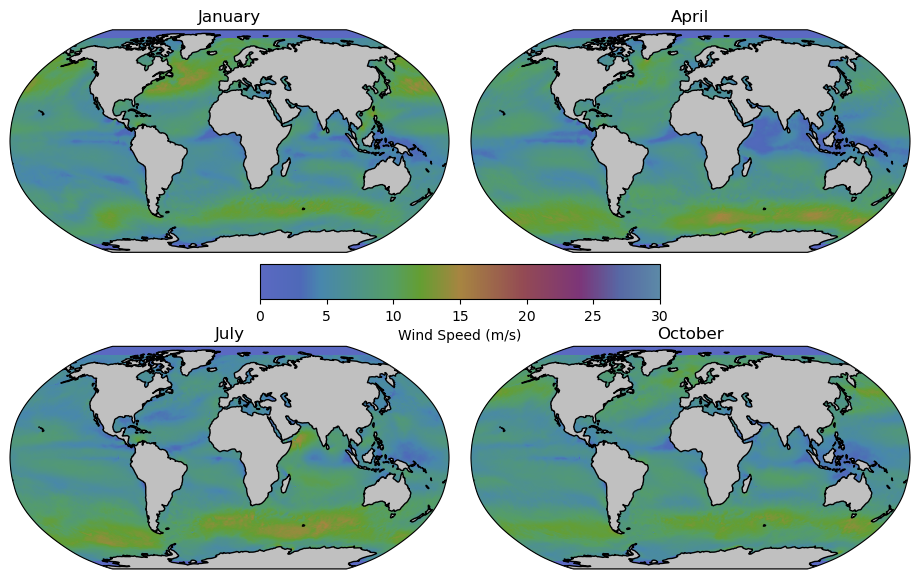

In [23]:
# create a figure with size (10,7)
fig = plt.figure(figsize=(10, 7))

# create a 2x2 GridSpec frame
# use a 5% border, 5% horizonal spacing and 1% vertical spacing
gs = GridSpec(2, 2, left=0.05, right=0.95, wspace=0.05, bottom=0.05, top=0.95, hspace=0.01)

# add an axis for the january field and plot it
ax1 = fig.add_subplot(gs[0,0], projection=ccrs.Robinson())
ax1.pcolormesh(longitude, latitude, january_average_windspeed,
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax1.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax1.set_title('January')

# add an axis for the april field and plot it
ax2 = fig.add_subplot(gs[0,1], projection=ccrs.Robinson())
ax2.pcolormesh(longitude, latitude, april_average_windspeed,
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax2.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax2.set_title('April')

# add an axis for the july field and plot it
ax3 = fig.add_subplot(gs[1,0], projection=ccrs.Robinson())
ax3.pcolormesh(longitude, latitude, july_average_windspeed,
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax3.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax3.set_title('July')

# add an axis for the october field and plot it
ax4 = fig.add_subplot(gs[1,1], projection=ccrs.Robinson())
C = ax4.pcolormesh(longitude, latitude, october_average_windspeed,
               vmin=0, vmax=30, cmap=windy_cmap, transform=ccrs.PlateCarree())
ax4.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
ax4.set_title('October')

# add a colorbar axis
# color bar axis is set by x and y, and then width and height
# x = 0.3, y = 0.5
# use width = 0.4, height = 0.05
cax = fig.add_axes([0.3, 0.5, 0.4, 0.05])
fig.colorbar(C, cax=cax, orientation='horizontal')
cax.set_xlabel('Wind Speed (m/s)');

### &#129300; Putting it all together
The above examples show how to plot data geographically and organize plots in subpanels of a figure. And in the previous labs, we generated time series from a collection of files. Let's put all of these ideas together. In your region of interest, generate a figures which has 3-4 projected map panels showing wind data through time. Then, in the same figure, make a time series which show the wind speed in your region of interest. Be sure to provide indications in your time series (with annotations) where you map panels fall along your time series.